In [2]:
from utils.dataset_loader import *
from utils.tools import get_emotion_by_label

In [2]:
import os
sub_id = "sub040"
mat_path = os.path.join(label_dir, sub_id, 'After_remarks.mat')
mat = loadmat(mat_path)
after_remark = mat['After_remark']
raw_scores = after_remark['score'].squeeze()
raw_vids = after_remark['vid'].squeeze()
scores = np.array([s.squeeze() for s in raw_scores])
vids = np.array([v.squeeze() for v in raw_vids])
print("scores.shape:",scores.shape)
print("vids.shape:",vids.shape)
sorted_idx = np.argsort(vids)
sorted_scores = scores[sorted_idx]
print("Sample Scores:",sorted_scores[0])
labels = np.argmax(sorted_scores, axis=1)
print("related label based on max of scores:",labels[0],"=",get_emotion_by_label(labels[0]))
limited_sorted_scores = scores[sorted_idx, :8]
limited_labels = np.argmax(limited_sorted_scores, axis=1)
print("Sample Scores:",limited_sorted_scores[0])
print("related label based on max of scores:",limited_labels[0],"=",get_emotion_by_label(limited_labels[0]))

scores.shape: (28, 12)
vids.shape: (28,)
Sample Scores: [0.03170166 0.03927816 0.03543294 0.03321126 3.05874023 0.36760254
 0.00586751 0.00900065 4.23642985 2.8765625  4.25386149 2.74579671]
related label based on max of scores: 10 = familiarity
Sample Scores: [0.03170166 0.03927816 0.03543294 0.03321126 3.05874023 0.36760254
 0.00586751 0.00900065]
related label based on max of scores: 4 = anger


# Load labels

In [3]:
subjects = sorted([f.split(".")[0] for f in os.listdir(processed_dir) if f.endswith(".pkl")])
y_all = []
scores_all = []
limited_scores_all = []
limited_y_all = []
vids_all = []
sorted_vids_all = []

for sub_id in subjects:
    mat_path = os.path.join(label_dir, sub_id, 'After_remarks.mat')
    mat = loadmat(mat_path)
    after_remark = mat['After_remark']
    raw_scores = after_remark['score'].squeeze()
    raw_vids = after_remark['vid'].squeeze()
    scores = np.array([s.squeeze() for s in raw_scores])        # (28, 12)
    vids = np.array([v.squeeze() for v in raw_vids])            # (28,)
    sorted_idx = np.argsort(vids)
    sorted_scores = scores[sorted_idx]
    labels = np.argmax(sorted_scores, axis=1)
    limited_sorted_scores = scores[sorted_idx, :8]
    limited_labels = np.argmax(limited_sorted_scores, axis=1)
    y_all.append(labels)
    limited_y_all.append(limited_labels)
    scores_all.append(scores)
    limited_scores_all.append(limited_sorted_scores)
    sorted_vids = vids[sorted_idx]
    vids_all.append(vids)
    sorted_vids_all.append(sorted_vids)


y_all = np.array(y_all)
limited_y_all = np.array(limited_y_all)
scores_all = np.array(scores_all)
limited_scores_all = np.array(limited_scores_all)
print(y_all.shape)
print(y_all[0].shape)
print(y_all[0])

(123, 28)
(28,)
[ 4  4  4  5  8  5  6  6  8  7  7  1  9  9  9  9  3  3  3  9  2  2  1 11
 10  1  9  1]


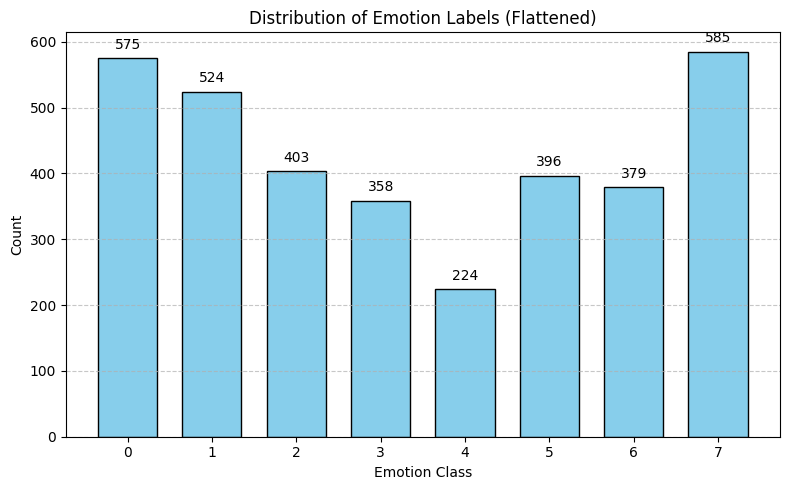

In [4]:
import matplotlib.pyplot as plt
import numpy as np

flat_labels = limited_y_all.flatten()
num_classes = len(np.unique(flat_labels))

plt.figure(figsize=(8, 5))
counts, bins, patches = plt.hist(
    flat_labels, bins=np.arange(num_classes + 1) - 0.5,
    rwidth=0.7, color='skyblue', edgecolor='black'
)

plt.xticks(range(num_classes))
plt.xlabel("Emotion Class")
plt.ylabel("Count")
plt.title("Distribution of Emotion Labels (Flattened)")
plt.grid(axis='y', linestyle='--', alpha=0.7)

for i, count in enumerate(counts):
    plt.text(i, count + 10, str(int(count)), ha='center', va='bottom')

plt.tight_layout()
plt.show()


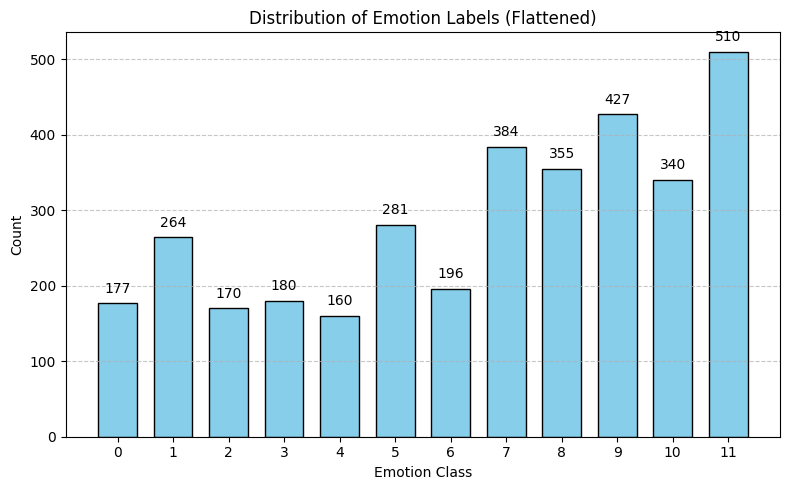

In [5]:
import matplotlib.pyplot as plt
import numpy as np

flat_labels = y_all.flatten()
num_classes = len(np.unique(flat_labels))

plt.figure(figsize=(8, 5))
counts, bins, patches = plt.hist(
    flat_labels, bins=np.arange(num_classes + 1) - 0.5,
    rwidth=0.7, color='skyblue', edgecolor='black'
)

plt.xticks(range(num_classes))
plt.xlabel("Emotion Class")
plt.ylabel("Count")
plt.title("Distribution of Emotion Labels (Flattened)")
plt.grid(axis='y', linestyle='--', alpha=0.7)

for i, count in enumerate(counts):
    plt.text(i, count + 10, str(int(count)), ha='center', va='bottom')

plt.tight_layout()
plt.show()

# Sample Label and Scores

In [6]:
sub_id = "sub050"
mat_path = os.path.join(label_dir, sub_id, 'After_remarks.mat')
mat = loadmat(mat_path)
after_remark = mat['After_remark']
raw_scores = after_remark['score'].squeeze()
raw_vids = after_remark['vid'].squeeze()
scores = np.array([s.squeeze() for s in raw_scores])        # (28, 12)
vids = np.array([v.squeeze() for v in raw_vids])            # (28,)
sorted_idx = np.argsort(vids)
sorted_scores = scores[sorted_idx]
limited_sorted_scores = scores[sorted_idx, :8]
labels = np.argmax(sorted_scores, axis=1)
limited_labels = np.argmax(limited_sorted_scores, axis=1)

In [7]:
sorted_scores[0]

array([0.371875  , 0.35190837, 0.37976481, 0.29428711, 0.25409749,
       0.39839274, 0.31485189, 0.35281982, 0.58586833, 3.62313232,
       0.44407959, 4.79344482])

In [8]:
labels[0]

11

In [9]:
limited_sorted_scores[0]

array([0.371875  , 0.35190837, 0.37976481, 0.29428711, 0.25409749,
       0.39839274, 0.31485189, 0.35281982])

In [10]:
limited_labels[0]

5

In [36]:
import numpy as np
from collections import defaultdict

video_scores_dict = defaultdict(list)

for subject_scores, subject_vids in zip(scores_all, vids_all):
    for score, vid in zip(subject_scores, subject_vids):
        video_scores_dict[int(vid)].append(score)

video_avg_scores = {}
video_std_scores = {}
video_var_scores = {}

for vid in sorted(video_scores_dict.keys()):
    scores = np.array(video_scores_dict[vid])  # shape: (num_subjects, 12)
    video_avg_scores[vid] = scores.mean(axis=0)  # (12,)
    video_std_scores[vid] = scores.std(axis=0)   # (12,)
    video_var_scores[vid] = scores.var(axis=0) 


In [ ]:
import pandas as pd

emotion_labels = [
    "Joy", "Tenderness", "Inspiration", "Amusement", 
    "Anger", "Disgust", "Fear", "Sadness", 
    "Arousal", "Valence", "Familiarity", "Liking"
]

df = pd.DataFrame.from_dict(video_avg_scores, orient="index", columns=emotion_labels)
df.index.name = "Video"
df = df.sort_index()
display(df)


,Joy,Tenderness,Inspiration,Amusement,Anger,Disgust,Fear,Sadness,Arousal,Valence,Familiarity,Liking
Video,,,,,,,,,,,,
1,0.71,0.51,1.02,0.67,4.34,2.29,1.52,2.95,4.39,2.00,1.86,1.68
2,0.45,0.47,0.60,0.38,4.99,3.55,2.17,4.49,4.55,1.51,2.60,1.41
3,0.50,0.35,0.78,0.63,5.40,2.77,2.75,5.25,5.07,1.60,3.09,1.30
4,0.92,0.56,0.55,1.61,0.98,5.53,2.24,1.38,4.41,1.64,0.92,0.91
5,0.69,0.83,0.73,0.61,0.84,4.25,3.47,1.48,3.87,1.71,1.42,1.43
6,0.60,0.43,0.49,0.65,1.04,5.21,3.36,1.53,4.15,1.57,1.10,1.13
7,0.60,0.85,0.64,0.59,1.64,1.27,4.52,2.06,4.23,1.65,1.73,1.82
8,0.57,0.48,0.55,0.48,1.15,2.33,4.66,2.12,4.55,1.48,2.45,1.57
9,0.74,0.53,0.59,1.00,1.75,3.72,4.09,2.24,4.22,1.57,1.34,1.55


In [24]:
main_emotion_labels = [
    "Joy", "Tenderness", "Inspiration", "Amusement", 
    "Anger", "Disgust", "Fear", "Sadness"
]

limited_df = df[main_emotion_labels]
display(limited_df)


,Joy,Tenderness,Inspiration,Amusement,Anger,Disgust,Fear,Sadness
Video,,,,,,,,
1,0.71,0.51,1.02,0.67,4.34,2.29,1.52,2.95
2,0.45,0.47,0.60,0.38,4.99,3.55,2.17,4.49
3,0.50,0.35,0.78,0.63,5.40,2.77,2.75,5.25
4,0.92,0.56,0.55,1.61,0.98,5.53,2.24,1.38
5,0.69,0.83,0.73,0.61,0.84,4.25,3.47,1.48
6,0.60,0.43,0.49,0.65,1.04,5.21,3.36,1.53
7,0.60,0.85,0.64,0.59,1.64,1.27,4.52,2.06
8,0.57,0.48,0.55,0.48,1.15,2.33,4.66,2.12
9,0.74,0.53,0.59,1.00,1.75,3.72,4.09,2.24


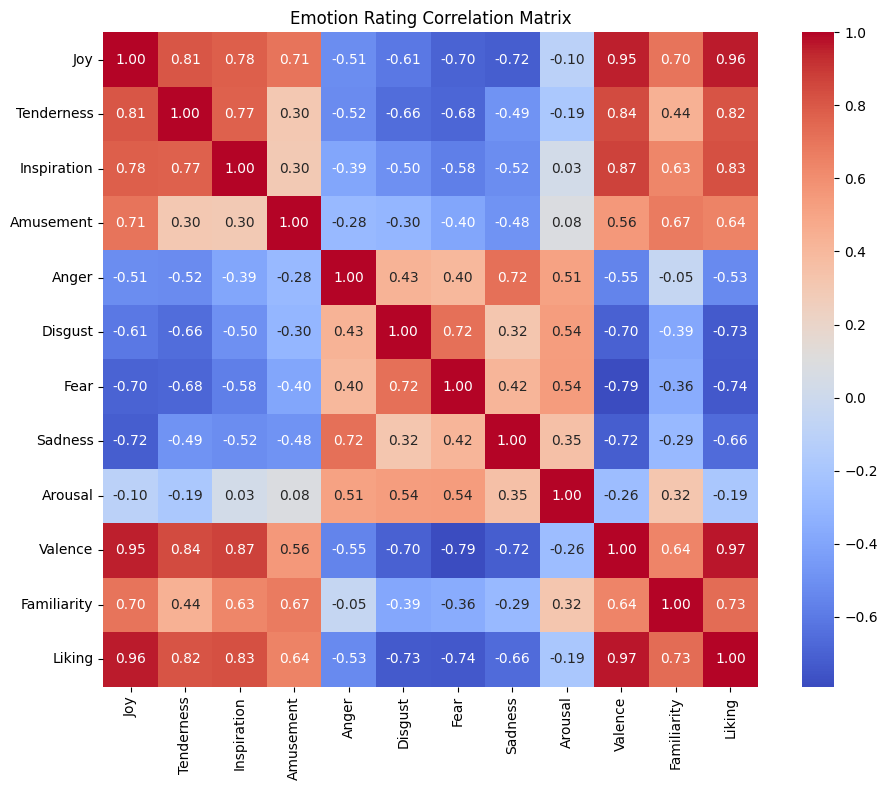

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", square=True)
plt.title("Emotion Rating Correlation Matrix")
plt.tight_layout()
plt.show()


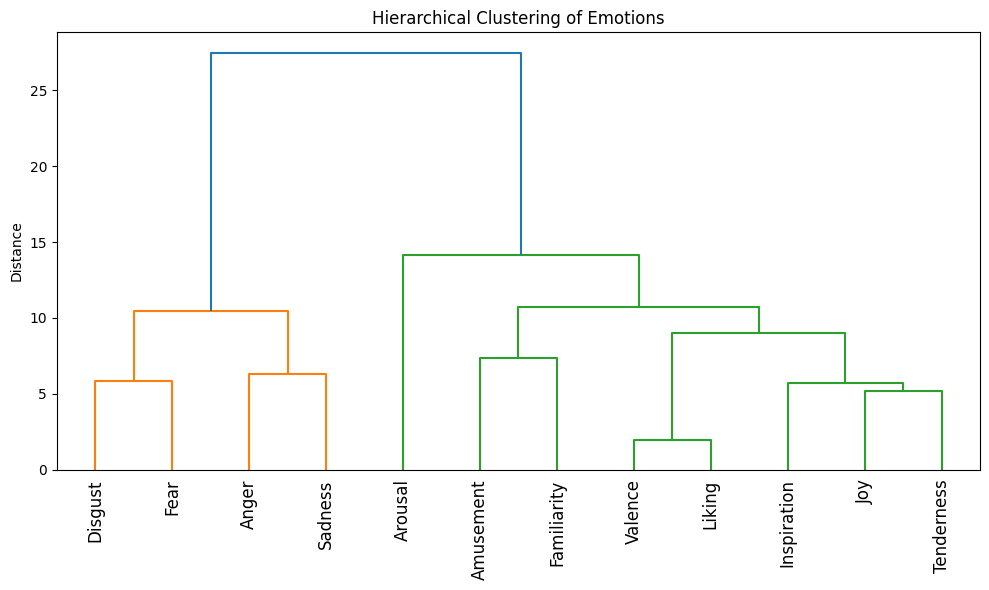

In [18]:
from scipy.cluster.hierarchy import linkage, dendrogram

plt.figure(figsize=(10, 6))
link = linkage(df.T, method='ward')
dendrogram(link, labels=df.columns, leaf_rotation=90)
plt.title("Hierarchical Clustering of Emotions")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()


In [26]:
df.shape

(28, 12)

In [27]:
limited_df.shape

(28, 8)

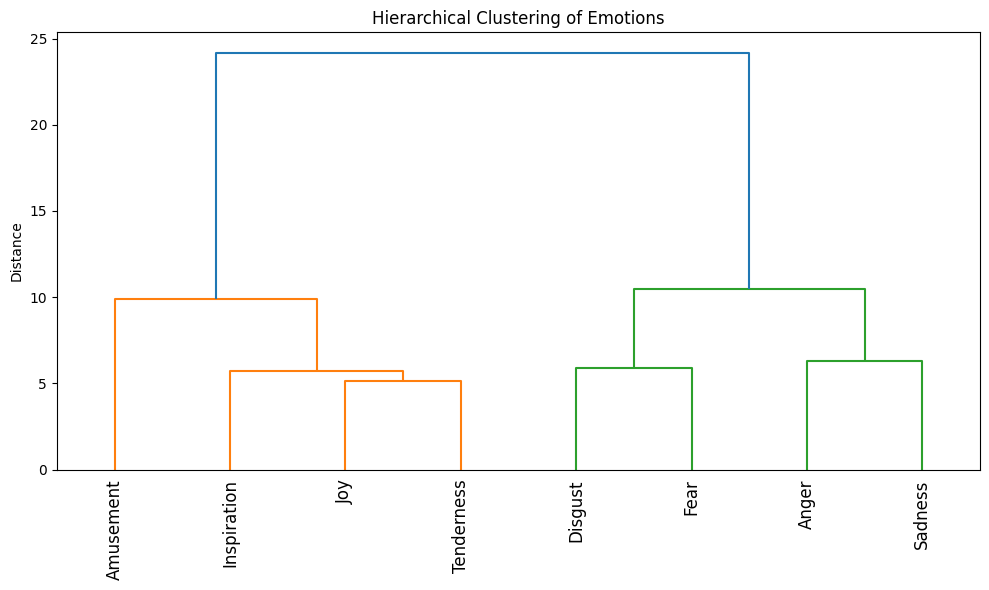

In [28]:
from scipy.cluster.hierarchy import linkage, dendrogram

plt.figure(figsize=(10, 6))
link = linkage(limited_df.T, method='ward')
dendrogram(link, labels=limited_df.columns, leaf_rotation=90)
plt.title("Hierarchical Clustering of Emotions")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()


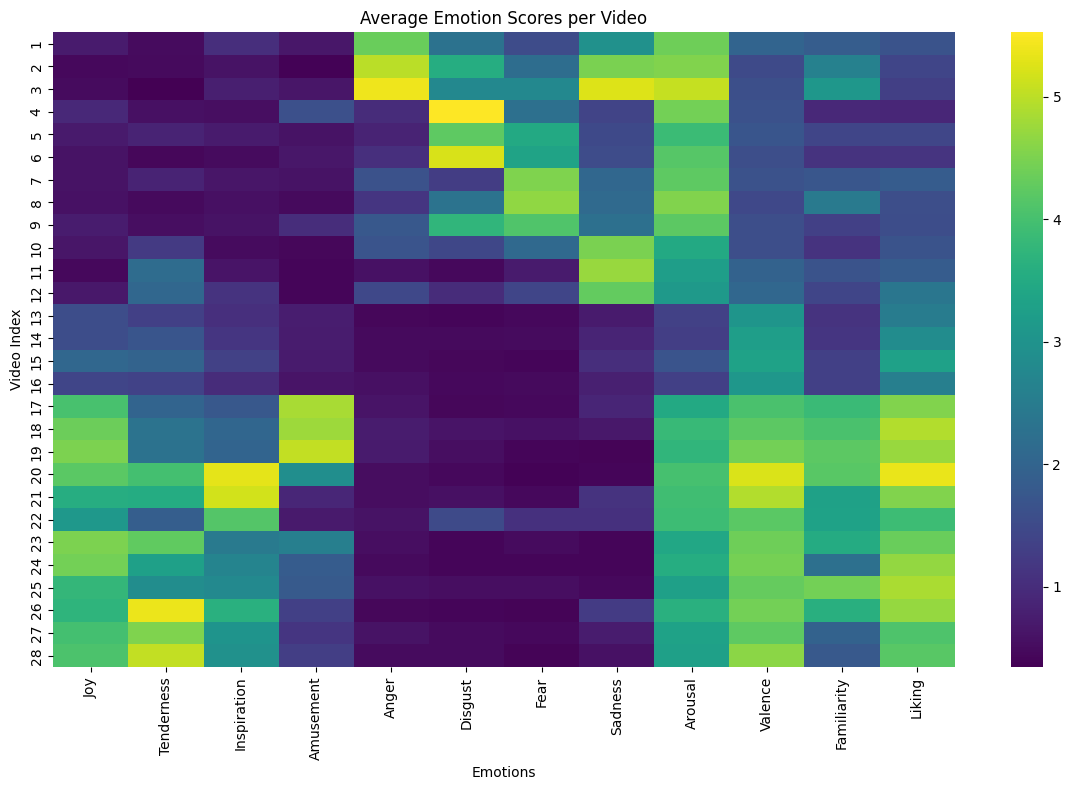

In [29]:
plt.figure(figsize=(12, 8))
sns.heatmap(df, annot=False, cmap='viridis', xticklabels=True, yticklabels=True)
plt.title("Average Emotion Scores per Video")
plt.xlabel("Emotions")
plt.ylabel("Video Index")
plt.tight_layout()
plt.show()

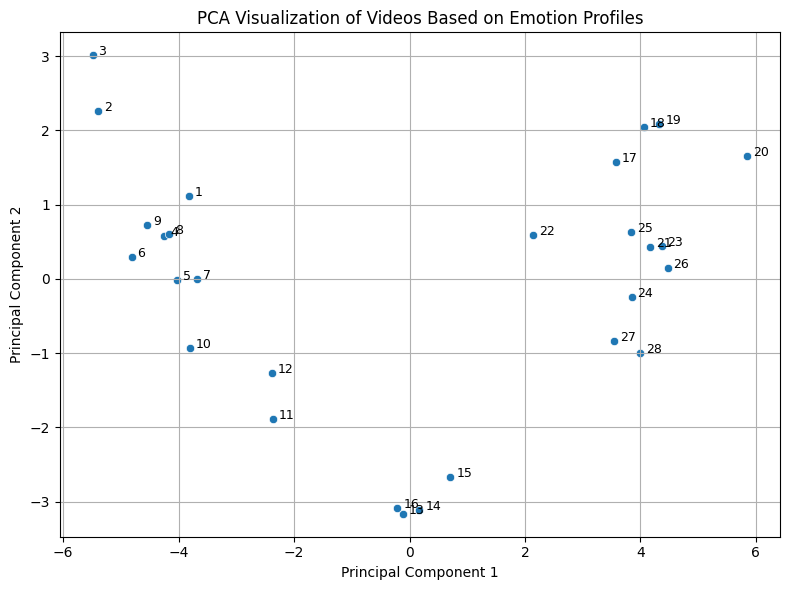

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_result = pca.fit_transform(df)

df_pca = pd.DataFrame(pca_result, columns=['PC1', 'PC2'])
df_pca['Video'] = df.index

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_pca, x='PC1', y='PC2')
for i, row in df_pca.iterrows():
    plt.text(row['PC1'] + 0.1, row['PC2'], str(i + 1), fontsize=9)
plt.title("PCA Visualization of Videos Based on Emotion Profiles")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.tight_layout()
plt.show()


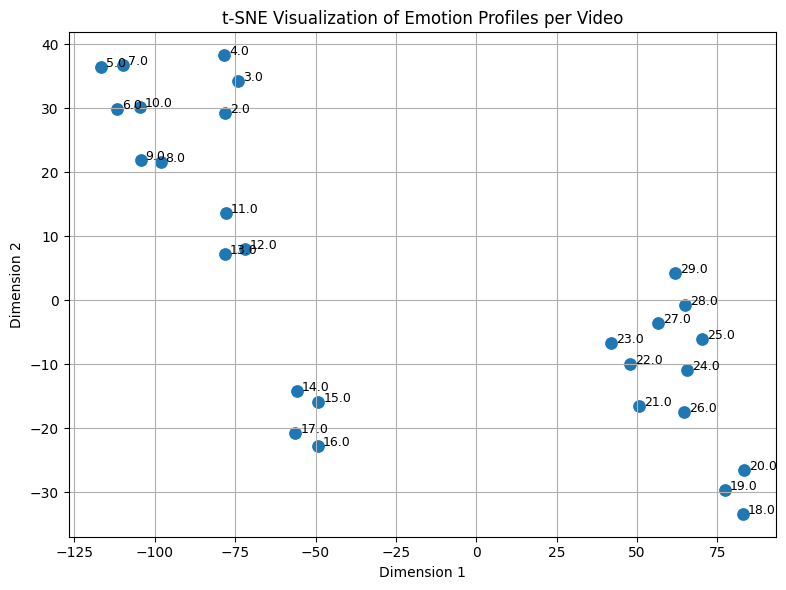

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

tsne = TSNE(n_components=2, perplexity=5, learning_rate=100, random_state=42)

tsne_result = tsne.fit_transform(df)

df_tsne = pd.DataFrame(tsne_result, columns=['Dim1', 'Dim2'])
df_tsne['Video'] = df.index

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_tsne, x='Dim1', y='Dim2', s=100)
for i, row in df_tsne.iterrows():
    plt.text(row['Dim1'] + 1.5, row['Dim2'], str(row['Video'] + 1), fontsize=9)
plt.title("t-SNE Visualization of Emotion Profiles per Video")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.grid(True)
plt.tight_layout()
plt.show()


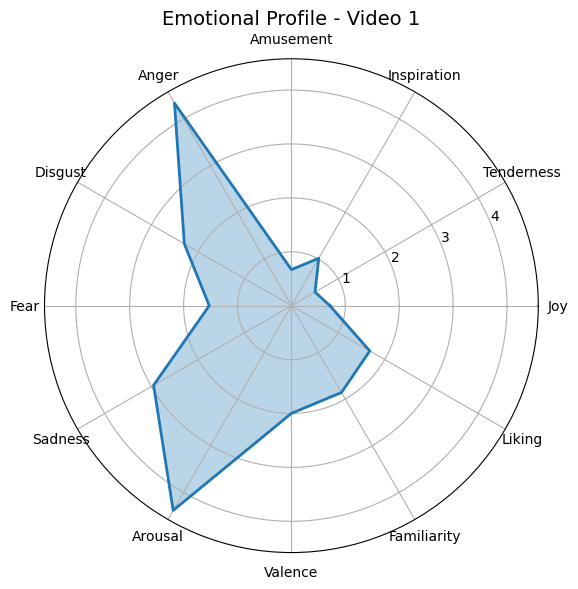

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

video_index = 0
profile = df.iloc[video_index].values
labels = df.columns.tolist()

angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
profile = np.concatenate((profile, [profile[0]]))
angles += [angles[0]]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={'polar': True})
ax.plot(angles, profile, color='tab:blue', linewidth=2)
ax.fill(angles, profile, color='tab:blue', alpha=0.3)
ax.set_title(f"Emotional Profile - Video {video_index + 1}", size=14)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=10)
ax.grid(True)
plt.tight_layout()
plt.show()


In [35]:
for i in range(len(df)):
    profile = df.iloc[i].values
    angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
    profile = np.concatenate((profile, [profile[0]]))
    angles += [angles[0]]

    fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={'polar': True})
    ax.plot(angles, profile, color='tab:blue', linewidth=2)
    ax.fill(angles, profile, color='tab:blue', alpha=0.3)
    ax.set_title(f"Video {i+1} Emotional Profile", size=14)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels, fontsize=10)
    ax.grid(True)
    plt.tight_layout()
    plt.savefig(f"results/video_profiles/profile_video_{i+1}.png")
    plt.close()


In [ ]:
import pandas as pd

data = []
for vid in sorted(video_scores_dict.keys()):
    row = {
        "Video": vid,
        **{f"{label}_mean": video_avg_scores[vid][i] for i, label in enumerate(labels)},
        **{f"{label}_std": video_std_scores[vid][i] for i, label in enumerate(labels)},
        **{f"{label}_var": video_var_scores[vid][i] for i, label in enumerate(labels)},
    }
    data.append(row)

df_stats = pd.DataFrame(data).set_index("Video")
df_stats.head()


,Joy_mean,Tenderness_mean,Inspiration_mean,Amusement_mean,Anger_mean,Disgust_mean,Fear_mean,Sadness_mean,Arousal_mean,Valence_mean,...,Inspiration_var,Amusement_var,Anger_var,Disgust_var,Fear_var,Sadness_var,Arousal_var,Valence_var,Familiarity_var,Liking_var
Video,,,,,,,,,,,,,,,,,,,,,
1,0.71,0.51,1.02,0.67,4.34,2.29,1.52,2.95,4.39,2.00,...,2.92,1.80,4.74,5.10,3.80,5.28,2.94,3.21,4.53,2.91
2,0.45,0.47,0.60,0.38,4.99,3.55,2.17,4.49,4.55,1.51,...,1.66,1.04,4.21,6.26,5.50,4.96,3.07,2.68,5.41,3.04
3,0.50,0.35,0.78,0.63,5.40,2.77,2.75,5.25,5.07,1.60,...,2.51,2.43,4.02,6.76,6.49,3.94,2.90,3.39,5.43,2.88
4,0.92,0.56,0.55,1.61,0.98,5.53,2.24,1.38,4.41,1.64,...,1.22,3.79,2.82,3.30,4.96,3.82,3.45,2.19,2.24,1.45
5,0.69,0.83,0.73,0.61,0.84,4.25,3.47,1.48,3.87,1.71,...,1.67,1.26,2.06,5.55,5.75,3.68,3.53,2.25,3.57,3.13


In [76]:
std_df = df_stats[df_stats.columns[12:24]]

In [77]:
display(std_df)

,Joy_std,Tenderness_std,Inspiration_std,Amusement_std,Anger_std,Disgust_std,Fear_std,Sadness_std,Arousal_std,Valence_std,Familiarity_std,Liking_std
Video,,,,,,,,,,,,
1,1.32,1.07,1.71,1.34,2.18,2.26,1.95,2.30,1.71,1.79,2.13,1.71
2,1.11,1.11,1.29,1.02,2.05,2.50,2.35,2.23,1.75,1.64,2.33,1.74
3,1.29,0.88,1.58,1.56,2.00,2.60,2.55,1.99,1.70,1.84,2.33,1.70
4,1.51,1.20,1.10,1.95,1.68,1.82,2.23,1.95,1.86,1.48,1.50,1.20
5,1.28,1.35,1.29,1.12,1.44,2.36,2.40,1.92,1.88,1.50,1.89,1.77
6,1.17,0.92,1.10,1.26,1.62,2.02,2.46,2.01,2.05,1.61,1.61,1.64
7,1.15,1.29,1.22,1.26,1.93,1.75,2.02,2.21,1.70,1.50,2.25,2.00
8,1.21,1.10,1.18,1.16,1.79,2.22,2.14,2.24,1.81,1.45,2.47,1.80
9,1.37,1.08,1.17,1.77,2.08,2.33,2.21,2.21,2.00,1.50,1.94,1.88


In [78]:
var_df = df_stats[df_stats.columns[24:]]

In [79]:
display(var_df)

,Joy_var,Tenderness_var,Inspiration_var,Amusement_var,Anger_var,Disgust_var,Fear_var,Sadness_var,Arousal_var,Valence_var,Familiarity_var,Liking_var
Video,,,,,,,,,,,,
1,1.75,1.15,2.92,1.80,4.74,5.10,3.80,5.28,2.94,3.21,4.53,2.91
2,1.23,1.22,1.66,1.04,4.21,6.26,5.50,4.96,3.07,2.68,5.41,3.04
3,1.67,0.78,2.51,2.43,4.02,6.76,6.49,3.94,2.90,3.39,5.43,2.88
4,2.28,1.43,1.22,3.79,2.82,3.30,4.96,3.82,3.45,2.19,2.24,1.45
5,1.63,1.81,1.67,1.26,2.06,5.55,5.75,3.68,3.53,2.25,3.57,3.13
6,1.38,0.84,1.20,1.58,2.62,4.09,6.07,4.05,4.20,2.60,2.59,2.68
7,1.31,1.66,1.50,1.59,3.72,3.06,4.08,4.88,2.89,2.25,5.08,3.99
8,1.47,1.21,1.38,1.35,3.19,4.92,4.59,5.00,3.26,2.09,6.09,3.24
9,1.88,1.16,1.37,3.15,4.32,5.44,4.89,4.90,3.99,2.25,3.77,3.53


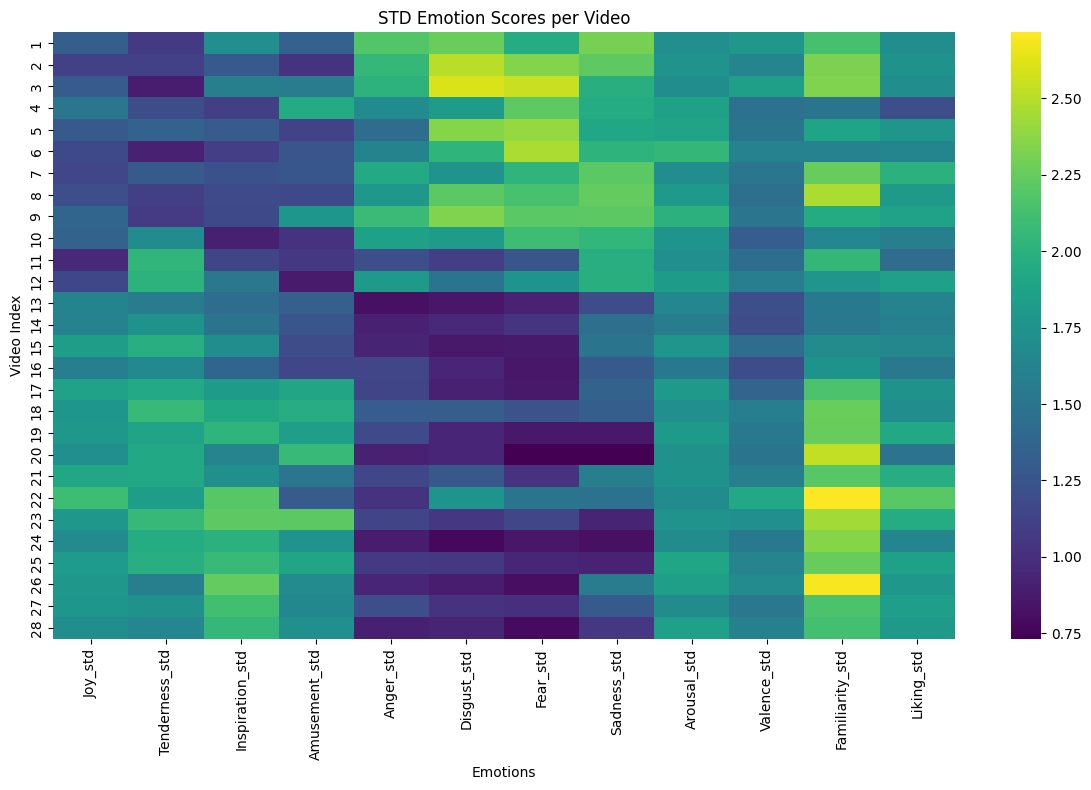

In [80]:
plt.figure(figsize=(12, 8))
sns.heatmap(std_df, annot=False, cmap='viridis', xticklabels=True, yticklabels=True)
plt.title("STD Emotion Scores per Video")
plt.xlabel("Emotions")
plt.ylabel("Video Index")
plt.tight_layout()
plt.show()

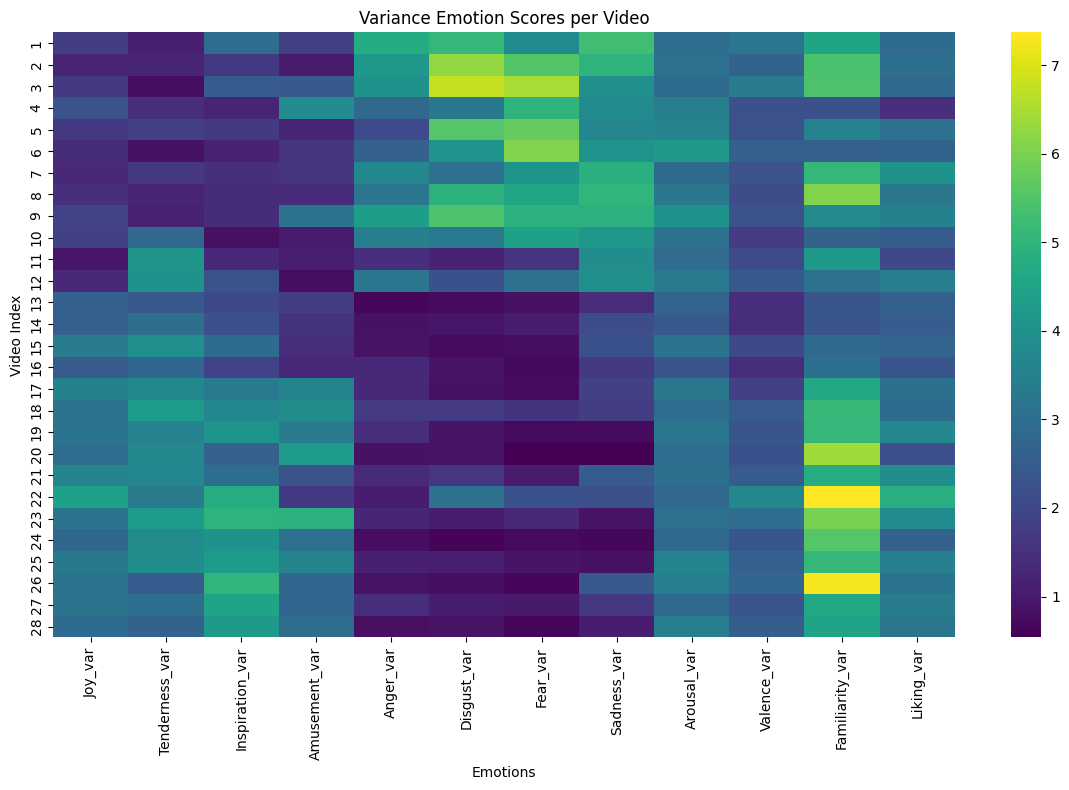

In [81]:
plt.figure(figsize=(12, 8))
sns.heatmap(var_df, annot=False, cmap='viridis', xticklabels=True, yticklabels=True)
plt.title("Variance Emotion Scores per Video")
plt.xlabel("Emotions")
plt.ylabel("Video Index")
plt.tight_layout()
plt.show()

In [82]:
std_df["total_std"] = std_df.sum(axis=1)
most_controversial_video = std_df["total_std"].idxmax()
top_videos = std_df.sort_values("total_std", ascending=False)
display(top_videos["total_std"])

C:\Users\rajab\AppData\Local\Temp\ipykernel_15584\3210166160.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  std_df["total_std"] = std_df.sum(axis=1)


Video
3     22.03
22    21.69
9     21.55
1     21.47
2     21.11
8     20.55
23    20.39
7     20.28
5     20.18
18    20.16
12    19.59
21    19.56
4     19.47
6     19.47
26    19.45
25    19.41
10    19.08
27    18.99
19    18.88
17    18.86
28    18.16
24    17.92
20    17.89
15    17.39
11    17.32
14    16.30
16    15.98
13    15.72
Name: total_std, dtype: float64

In [83]:
var_df["total_var"] = var_df.sum(axis=1)
most_controversial_video = var_df["total_var"].idxmax()
var_top_videos = var_df.sort_values("total_var", ascending=False)
display(var_top_videos["total_var"])

C:\Users\rajab\AppData\Local\Temp\ipykernel_15584\2854242622.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  var_df["total_var"] = var_df.sum(axis=1)


Video
3     43.21
22    41.52
9     40.65
2     40.29
1     40.13
8     37.78
23    37.58
7     36.01
5     35.89
18    35.12
26    34.85
25    33.92
6     33.89
21    33.25
12    33.21
4     32.95
19    32.31
10    31.90
27    31.67
17    31.66
20    30.18
24    29.89
28    29.89
15    26.93
11    26.76
14    22.98
16    22.17
13    21.67
Name: total_var, dtype: float64

# Preprocessing

In [2]:
def load_processed_data(processed_dir, label_dir, selected_subjects=None):
    X_all = []
    y_all = []

    subjects = get_subject_list(processed_dir, selected_subjects)

    for sub_file in subjects:
        sub_id = sub_file.split(".")[0]  # sub000
        eeg_path = os.path.join(processed_dir, sub_file)
        mat_path = os.path.join(label_dir, sub_id, 'After_remarks.mat')

        eeg_data = load_eeg_data(eeg_path)
        sorted_idx, labels = load_labels(mat_path)
        X, y = segment_reshape_eeg_data(eeg_data, sorted_idx, labels)

        X_all.extend(X)
        y_all.extend(y)

    return np.array(X_all), np.array(y_all)


In [3]:
X_all , y_all = load_processed_data(processed_dir,label_dir,["sub000"])

In [ ]:
import matplotlib.pyplot as plt

sample_raw = X_all[0][:, 0]  # shape: (250,)

X_filtered = apply_bandpass_filter(X_all, lowcut=1.0, highcut=50.0, fs=250, order=4)
sample_filtered = X_filtered[0][:, 0]


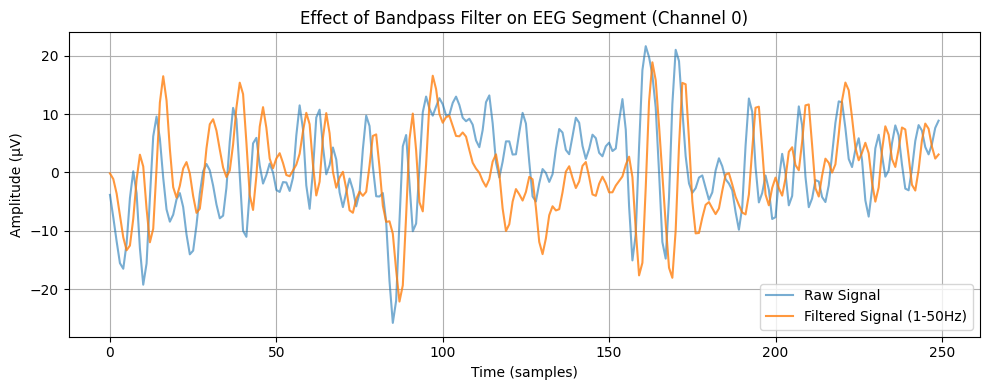

In [5]:
plt.figure(figsize=(10, 4))
plt.plot(sample_raw, label='Raw Signal', alpha=0.6)
plt.plot(sample_filtered, label='Filtered Signal (1-50Hz)', alpha=0.8)
plt.title("Effect of Bandpass Filter on EEG Segment (Channel 0)")
plt.xlabel("Time (samples)")
plt.ylabel("Amplitude (μV)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

sample_raw = X_all[0][:, 0]

X_filtered = baseline_correction(X_all,20)
sample_filtered = X_filtered[0][:, 0] 


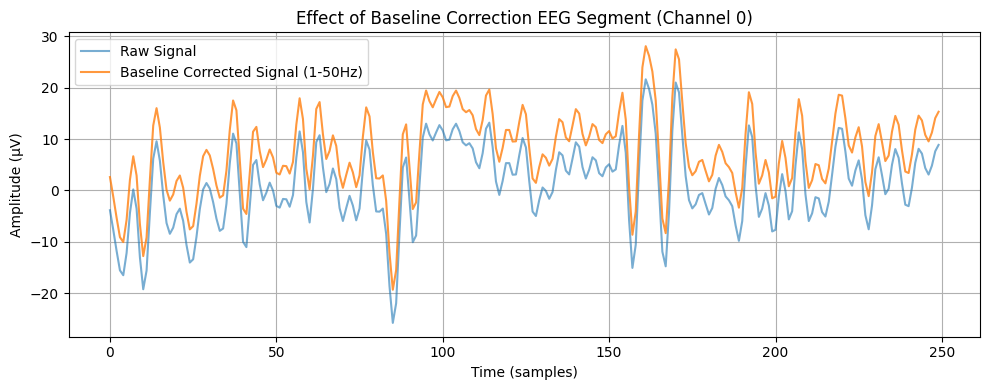

In [8]:
plt.figure(figsize=(10, 4))
plt.plot(sample_raw, label='Raw Signal', alpha=0.6)
plt.plot(sample_filtered, label='Baseline Corrected Signal (1-50Hz)', alpha=0.8)
plt.title("Effect of Baseline Correction EEG Segment (Channel 0)")
plt.xlabel("Time (samples)")
plt.ylabel("Amplitude (μV)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

sample_raw = X_all[0][:, 0]

X_filtered = apply_normalization(X_all,method="zscore")
sample_filtered = X_filtered[0][:, 0] 


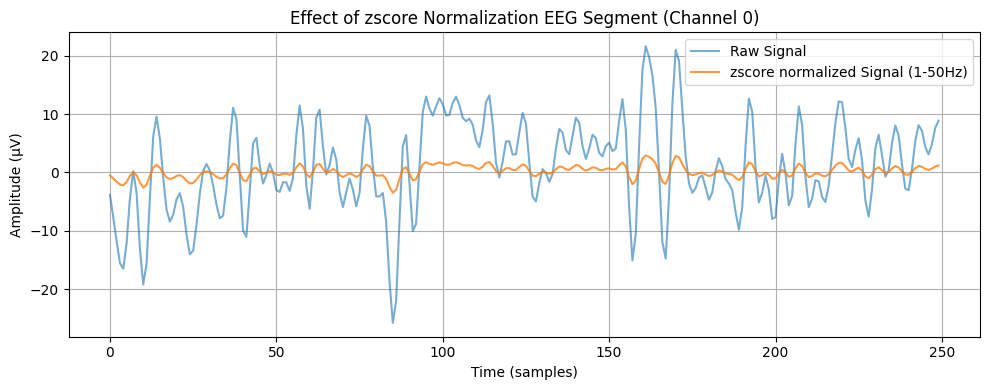

In [10]:
plt.figure(figsize=(10, 4))
plt.plot(sample_raw, label='Raw Signal', alpha=0.6)
plt.plot(sample_filtered, label='zscore normalized Signal (1-50Hz)', alpha=0.8)
plt.title("Effect of zscore Normalization EEG Segment (Channel 0)")
plt.xlabel("Time (samples)")
plt.ylabel("Amplitude (μV)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

sample_raw = X_all[0][:, 0]

X_filtered = apply_normalization(X_all,method="minmax")
sample_filtered = X_filtered[0][:, 0] 


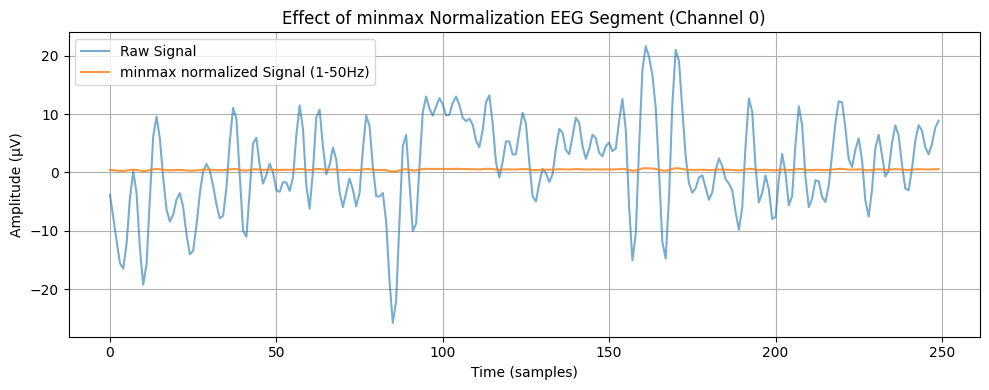

In [13]:
plt.figure(figsize=(10, 4))
plt.plot(sample_raw, label='Raw Signal', alpha=0.6)
plt.plot(sample_filtered, label='minmax normalized Signal (1-50Hz)', alpha=0.8)
plt.title("Effect of minmax Normalization EEG Segment (Channel 0)")
plt.xlabel("Time (samples)")
plt.ylabel("Amplitude (μV)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

sample_raw = X_all[0][:, 0]

X_filtered = apply_normalization(X_all,method="per_channel")
sample_filtered = X_filtered[0][:, 0] 


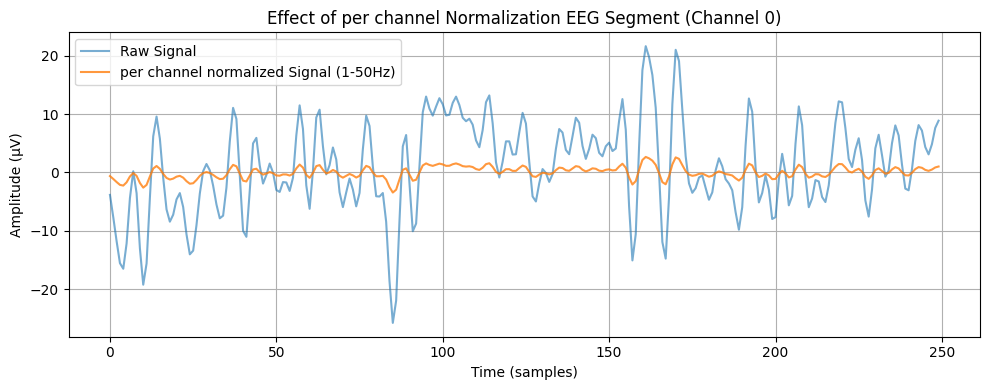

In [15]:
plt.figure(figsize=(10, 4))
plt.plot(sample_raw, label='Raw Signal', alpha=0.6)
plt.plot(sample_filtered, label='per channel normalized Signal (1-50Hz)', alpha=0.8)
plt.title("Effect of per channel Normalization EEG Segment (Channel 0)")
plt.xlabel("Time (samples)")
plt.ylabel("Amplitude (μV)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
